# Digital Detective: Feature Extraction Challenge
This interactive notebook allows you to run computer vision algorithms (ORB) to extract and match visual features between images, simulating a digital detective searching for clues.

In [3]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Helper function to display images properly in Jupyter/Colab
def show_img(title, img):
    plt.figure(figsize=(12, 8))
    # Convert BGR (OpenCV default) to RGB (Matplotlib default)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis('off')
    plt.show()

Images successfully loaded and converted to grayscale.


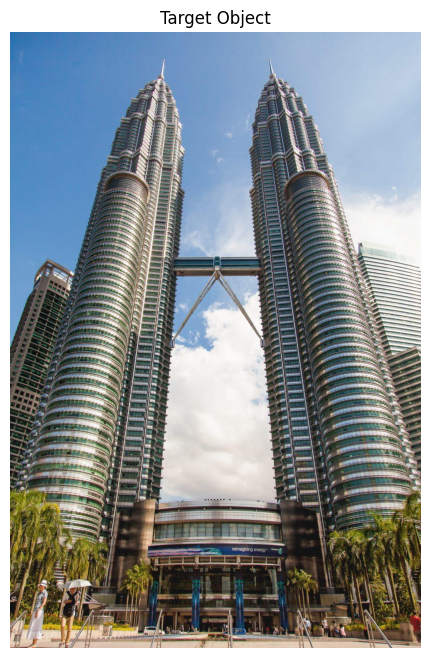

In [10]:
import urllib.request

# Load the target image and the scene from URLs
url_klcc = 'https://www.suriaklcc.com.my/wp-content/uploads/2022/01/Twin-Towers-1.jpg'
url_118 = 'https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcS9XubWRAe1L7eB1zE1gouQrZ8MI-Qmp5Y4gswLz3GLlA&s'

def download_image(url):
    try:
        req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
        resp = urllib.request.urlopen(req)
        image_bytes = np.asarray(bytearray(resp.read()), dtype="uint8")
        return cv2.imdecode(image_bytes, cv2.IMREAD_COLOR)
    except Exception as e:
        print(f"Error downloading {url}: {e}")
        return None

img_cup = download_image(url_klcc)
img_table = download_image(url_118)

if img_cup is None or img_table is None:
    print("Error: Could not load images. Please check the URLs or your connection.")
else:
    # Convert to grayscale (feature extraction works best on intensity, not color)
    gray_cup = cv2.cvtColor(img_cup, cv2.COLOR_BGR2GRAY)
    gray_table = cv2.cvtColor(img_table, cv2.COLOR_BGR2GRAY)
    print("Images successfully loaded and converted to grayscale.")
    show_img("Target Object", img_cup)


In [12]:
import cv2 # OpenCV library
import numpy as np
import urllib.request
import matplotlib.pyplot as plt

# Helper function to load an image from a URL as grayscale
def url_to_image_gray(url):
    try:
        resp = urllib.request.urlopen(url)
        image_bytes = np.asarray(bytearray(resp.read()), dtype="uint8")
        image = cv2.imdecode(image_bytes, cv2.IMREAD_GRAYSCALE)
        return image
    except Exception as e:
        print(f"Error loading {url}: {e}")
        return None

## Step 2: Extract Features using ORB
Here, the computer acts as the detective, identifying keypoints (distinctive corners and edges) and calculating their mathematical descriptors.

Loading images directly from URLs for Step 2 fallback...


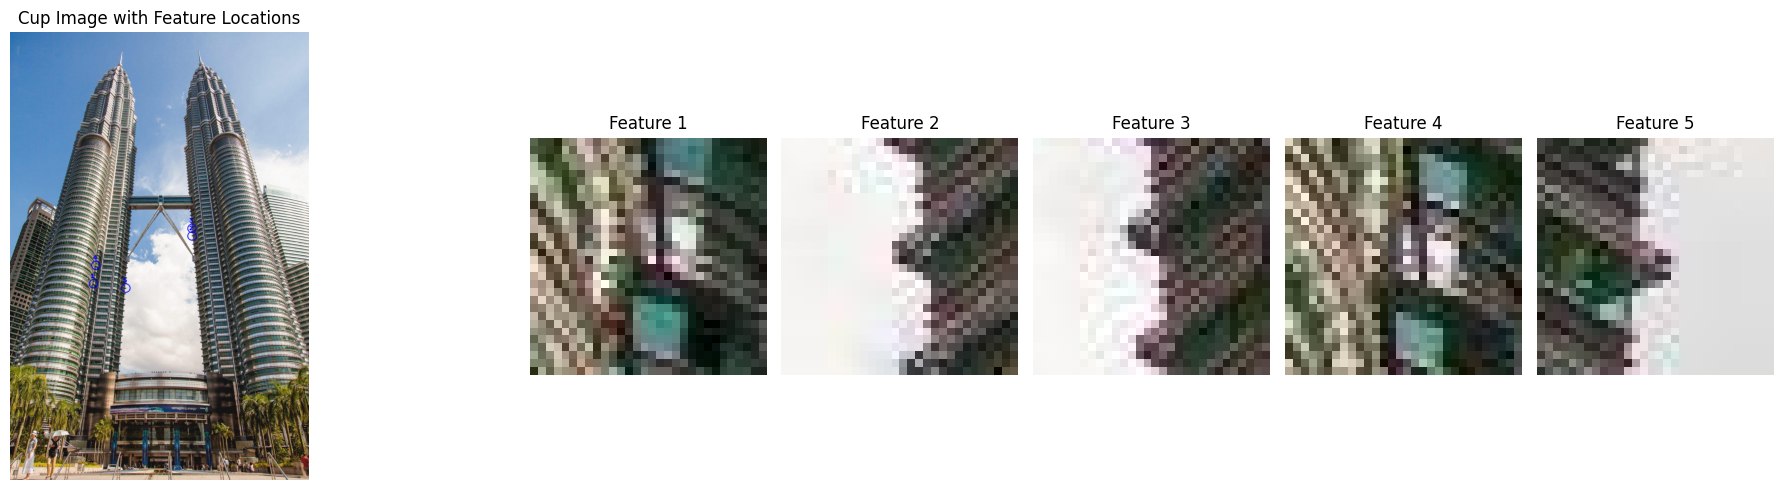

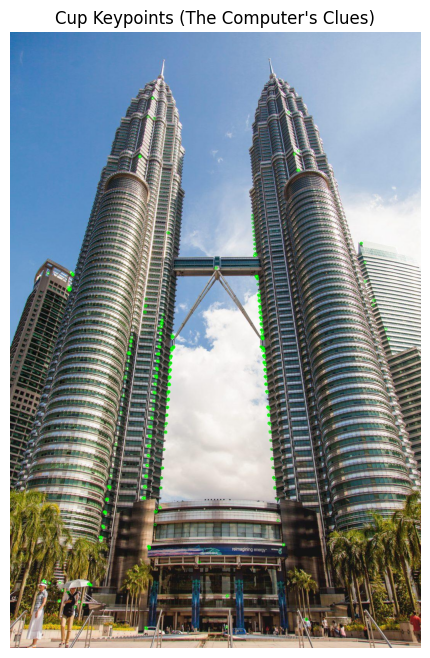

In [9]:
# Ensure variables are loaded before executing
if 'gray_cup' not in globals() or 'gray_table' not in globals():
    print("Loading images directly from URLs for Step 2 fallback...")
    import urllib.request
    url_klcc = 'https://www.suriaklcc.com.my/wp-content/uploads/2022/01/Twin-Towers-1.jpg'
    url_118 = 'https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcS9XubWRAe1L7eB1zE1gouQrZ8MI-Qmp5Y4gswLz3GLlA&s'

    def download_image(url):
        try:
            req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
            resp = urllib.request.urlopen(req)
            image_bytes = np.asarray(bytearray(resp.read()), dtype="uint8")
            return cv2.imdecode(image_bytes, cv2.IMREAD_COLOR)
        except Exception as e:
            return None

    img_cup = download_image(url_klcc)
    img_table = download_image(url_118)
    if img_cup is not None and img_table is not None:
        gray_cup = cv2.cvtColor(img_cup, cv2.COLOR_BGR2GRAY)
        gray_table = cv2.cvtColor(img_table, cv2.COLOR_BGR2GRAY)

# Initialize the ORB detector
orb = cv2.ORB_create(nfeatures=500)

if 'gray_cup' in globals() and 'gray_table' in globals():
    # Detect keypoints and compute descriptors
    kp_cup, des_cup = orb.detectAndCompute(gray_cup, None)
    kp_table, des_table = orb.detectAndCompute(gray_table, None)

    # Find the number of keypoints to visualize (maximum of 5)
    num_patches = min(5, len(kp_cup))

    if num_patches > 0:
        # Setup a figure with subplots dynamically sized based on actual keypoints found
        fig, axes = plt.subplots(1, num_patches + 1, figsize=(20, 5),
                                 gridspec_kw={'width_ratios': [3] + [1] * num_patches})

        # If only 1 patch is found, axes won't be indexable in the same way, so we wrap it
        if num_patches == 1:
            axes = [axes[0], axes[1]]

        # Create a copy of the original cup image to draw annotations on
        img_cup_annotated = img_cup.copy()
        offset = 15

        # Loop through the detected keypoints
        for i in range(num_patches):
            kp = kp_cup[i]
            x, y = int(kp.pt[0]), int(kp.pt[1])

            # Draw a numbered blue circle on the main image
            cv2.circle(img_cup_annotated, (x, y), offset, (255, 0, 0), 2)
            cv2.putText(img_cup_annotated, str(i+1), (x - 10, y - 20),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 0, 0), 2)

            # Crop the pixel patch safely
            patch = img_cup[max(0, y - offset) : min(img_cup.shape[0], y + offset),
                            max(0, x - offset) : min(img_cup.shape[1], x + offset)]

            # Display the cropped patch
            axes[i+1].imshow(cv2.cvtColor(patch, cv2.COLOR_BGR2RGB))
            axes[i+1].set_title(f"Feature {i+1}")
            axes[i+1].axis('off')

        # Display the annotated main image in the first subplot
        axes[0].imshow(cv2.cvtColor(img_cup_annotated, cv2.COLOR_BGR2RGB))
        axes[0].set_title("Cup Image with Feature Locations")
        axes[0].axis('off')

        plt.tight_layout()
        plt.show()
    else:
        print("No keypoints detected to visualize.")

    # Visualize all the keypoints found on the cup
    img_cup_kp = cv2.drawKeypoints(img_cup, kp_cup, None, color=(0, 255, 0), flags=0)
    show_img("Cup Keypoints (The Computer's Clues)", img_cup_kp)
else:
    print("Error: Could not load the required images. Please ensure the URLs are valid and reachable.")

## Step 3 & 4: Match Features and Analyze the Results
The computer now compares the descriptors from the cup against the descriptors found in the cluttered scene to find matches.

Total features matched: 87


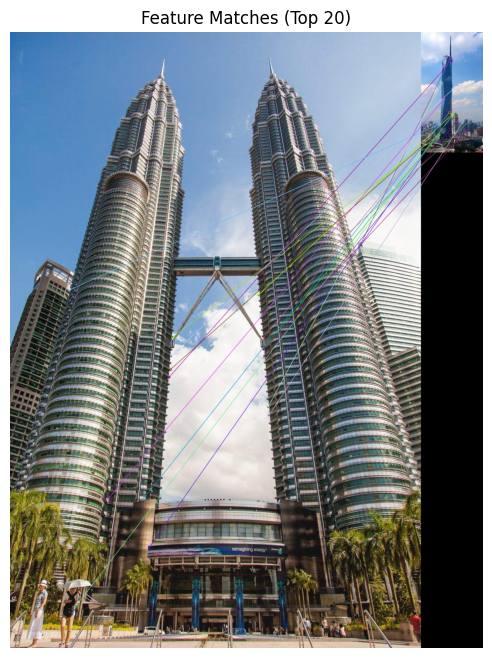

In [11]:
if 'des_cup' in globals() and 'des_table' in globals() and 'kp_cup' in globals() and 'kp_table' in globals():
    # Create a Brute-Force Matcher to compare descriptor distances (Hamming distance for ORB)
    bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)

    # Match descriptors between the cup and the table
    matches = bf.match(des_cup, des_table)

    # Sort the matches based on how similar they are (lower distance = better match)
    matches = sorted(matches, key=lambda x: x.distance)

    print(f"Total features matched: {len(matches)}")

    # Draw the top 20 best matches to avoid visual clutter
    img_matches = cv2.drawMatches(
        img_cup, kp_cup,
        img_table, kp_table,
        matches[:20], None,
        flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
    )

    show_img("Feature Matches (Top 20)", img_matches)
else:
    print("Error: Features have not been extracted yet. Please successfully run Step 2 first.")

### Reflection & Discussion

#### 1. Feature Effectiveness
* **Which feature was the most useful for finding the target object quickly?**
  Highly distinctive, high-contrast structural corners and sharp boundary junctions—such as the unique geometrical corners of the building's skybridge structure, distinct spire tips, or high-contrast window boundaries—are the most useful keypoints.
* **Why did it work so well?**
  These areas have intensity gradients changing in multiple directions (strong eigenvalues in the image gradient matrix). This makes them highly unique and geometrically localizable compared to flat regions or straight edges, leading to distinct descriptors that match reliably.

#### 2. Ambiguous Features
* **Did any group identify a feature that was ambiguous or accidentally matched the wrong object?**
  Repeated structural grid patterns, such as windows of uniform texture or horizontal/vertical lines, are often highly ambiguous. Because similar-looking patterns repeat throughout both images, the ORB descriptor vectors end up very close in feature space, leading to false matches on incorrect parts of the structures.

#### 3. Robustness Challenge
* **What happens when the target is rotated, or the lighting changes? Would your features still work?**
  * **Rotation:** ORB is designed to be rotation-invariant because it computes an intensity centroid orientation for each keypoint and aligns the descriptor accordingly. Thus, the features will still match well even if rotated.
  * **Lighting changes:** Extreme lighting or shadows can alter local gradient patterns and intensities, potentially degrading matching quality. While ORB's normalized descriptor provides some robustness to uniform lighting changes, severe direction-based illumination changes or shadows can prevent successful matching.